# Л1 — Підготовка даних

Велика частина роботи в Data Science — збір і підготовка даних. Саме тут виникає багато неочікуваних проблем і пасток.

Ноутбук нижче базово показує, як працювати з даними й готувати їх. Він не охоплює всіх можливих сценаріїв, а приклади в ньому часом сильно спрощені. Проте він дасть розуміння, де шукати помилки і як з ними боротися. Більше туторіалів — у [Kaggle Learn](https://www.kaggle.com/learn), зокрема [Data Cleaning](https://www.kaggle.com/learn/data-cleaning).

Базовий алгоритм підготовки даних може виглядати так (у дужках — кроки цього ноутбука):

- зчитування даних і початкове дослідження (1);
- дослідження структури й особливостей даних, зміна типів (2);
- об'єднання даних з різних джерел (3–4);
- робота з пропущеними й зламаними значеннями: drop, fill тощо (5, 7, 8);
- пошук outliers: drop, clip тощо (6);
- пошук зайвих і бракуючих колонок (9).

І головне: з кожною дією треба бути обережним. Outliers можуть бути реальними даними, які логічно пояснюються і які не можна видаляти. А пропущені значення можуть щось означати й бути корисними. Обидва випадки є в цій роботі.

Далі бувають кроки, специфічні для певних моделей чи алгоритмів:

- scaling: normalization, standardization тощо;
- обробка категорійних колонок: one-hot encoding тощо;
- dimensionality reduction.

Тут вони не розглядаються, частину з них побачите в Л2 і Л3.

Шаблон веде покроково: у кожному кроці — навіщо він і що зробити, у клітинці з `TODO` — ваш код. Опис даних і таблиця недоліків — у `README.md`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

## 1. Завантаження даних

На цьому етапі важливо впевнитися, що файли завантажено правильно, і подивитися, що взагалі всередині. Можуть допомогти `df.head()`, `df.tail()`, `df.shape` і `df.dtypes`.

Що ви маєте зрозуміти?

- Чи зчиталися дані взагалі?
- Чи правильно розпарсилися рядки, колонки й значення?
- Які типи в колонок?
- Які приблизно значення?
- Скільки рядків і колонок?

In [2]:
# TODO: завантажте meters.parquet і registry.csv свого варіанта з папки variants/<варіант>/

df_meters = pd.read_parquet("../variants/7/meters.parquet")
df_registry = pd.read_csv("../variants/7/registry.csv")

print("----meters:", df_meters.shape) #чи завантажилися дані взагалі; скільки в таблиці рядків і скільки колонок
print("----registry:", df_registry.shape)
print("\n----column types in meters: \n", df_meters.dtypes)
print("----column types in registry: \n",df_registry.dtypes)

print("\n----meters (first 3 rows): \n")
display(df_meters.head(3))
print("----registry (first 3 rows): \n")
display(df_registry.head(3))

display(df_meters.tail(3))

----meters: (516214, 4)
----registry: (800, 7)

----column types in meters: 
 meter_id                      str
ts                 datetime64[us]
consumption_kwh           float64
record_ts          datetime64[us]
dtype: object
----column types in registry: 
 meter_id              str
customer_type         str
tariff                str
electric_heating    int64
connection_year     int64
years_connected     int64
district              str
dtype: object

----meters (first 3 rows): 



,meter_id,ts,consumption_kwh,record_ts
0,UA101476,2026-01-05 00:00:00,1827.3,2026-01-05 00:08:04
1,UA101476,2026-01-05 01:00:00,1709.5,2026-01-05 01:12:38
2,UA101476,2026-01-05 02:00:00,1799.1,2026-01-05 02:10:58


----registry (first 3 rows): 



,meter_id,customer_type,tariff,electric_heating,connection_year,years_connected,district
0,UA101476,household,dual_zone,1,1998,28,Obolon
1,UA101604,small_business,single,0,2005,21,Sviatoshyn
2,UA102933,household,dual_zone,0,2015,10,Darnytsia


,meter_id,ts,consumption_kwh,record_ts
516211,UA998904,2026-02-01 21:00:00,1.6958,2026-02-01 21:10:43
516212,UA998904,2026-02-01 22:00:00,1.3335,2026-02-01 22:09:07
516213,UA998904,2026-02-01 23:00:00,1.0762,2026-02-01 23:07:09


## 2. Звірка з описом

Іноді бізнес надає опис ідеальних даних, але реальні дані часто з ним не збігаються. Тому спершу подивіться, чи ваші дані відповідають опису в `README.md`. Може допомогти `df.describe()`.

Перевірте (але поки не виправляйте):

- типи колонок: якщо число прочиталося як текст, частина операцій спрацює неправильно;
- скільки рядків мають `customer_type`, `tariff` чи `electric_heating`, яких немає в описі;
- скільки рядків мають `ts`, `connection_year` чи `years_connected` поза межами з опису;
- скільки різних лічильників у кожному файлі — мають бути по 800.

Можуть допомогти `isin`, `between` і `nunique`.

Недоліки з таблиці в `README.md` перевірятимете далі, кожен у своєму кроці. Межі споживання залежать від типу абонента, а тип є лише в реєстрі, тому їх перевірите після об'єднання, на кроці 6.

In [3]:
# Жодне число не прочиталося як текст, жоден текст не став числом 

# min і max через describe()
print("----meters describe: \n")
display(df_meters.describe())
print("----registry describe: \n")
display(df_registry.describe())

#кількість неправильних рядків
invalid_tariffs = (~df_registry["tariff"].isin(["single", "dual_zone"])).sum()
print("---- number of invalid rows in tariffs:", invalid_tariffs)

invalid_types = (~df_registry["customer_type"].isin(["household", "small_business", "industrial"])).sum()
print("---- number of invalid rows in customer_type:", invalid_types)

invalid_heating = (~df_registry["electric_heating"].isin([0, 1])).sum()
print("---- number of invalid rows in electric_heating:", invalid_heating)

invalid_ts = (~df_meters["ts"].between(pd.Timestamp("2026-01-05 00:00"),pd.Timestamp("2026-02-01 23:00"))).sum()
print("---- number of invalid rows in ts:", invalid_ts)

invalid_connection_year = (~df_registry["connection_year"].between(1985, 2024)).sum()
print("---- number of invalid rows in connection_year:", invalid_connection_year)

invalid_years_connected = (~df_registry["years_connected"].between(1,41)).sum()
print("---- number of invalid rows in years_connected:", invalid_years_connected)

print("---- unique meters in meters:", df_meters["meter_id"].nunique())
print("---- unique meters in registry:", df_registry["meter_id"].nunique())

----meters describe: 



,ts,consumption_kwh,record_ts
count,516214,516214.000000,516214
mean,2026-01-18 18:33:55.841724,237.310519,2026-01-18 18:41:54.955177
min,2026-01-05 00:00:00,0.023100,2026-01-05 00:01:00
25%,2026-01-11 19:00:00,0.389300,2026-01-11 19:11:13
50%,2026-01-18 15:00:00,0.852700,2026-01-18 15:12:27.500000
75%,2026-01-25 17:00:00,2.632800,2026-01-25 17:10:43
max,2026-02-01 23:00:00,90672.300000,2026-02-01 23:14:59
std,NaN,2182.738692,NaN


----registry describe: 



,electric_heating,connection_year,years_connected
count,800.000000,800.000000,800.000000
mean,0.211250,2004.461250,21.083750
std,0.408451,11.909694,11.905205
min,0.000000,1985.000000,1.000000
25%,0.000000,1994.000000,10.750000
50%,0.000000,2004.000000,21.000000
75%,0.000000,2015.000000,31.000000
max,1.000000,2024.000000,41.000000


---- number of invalid rows in tariffs: 0
---- number of invalid rows in customer_type: 0
---- number of invalid rows in electric_heating: 0
---- number of invalid rows in ts: 0
---- number of invalid rows in connection_year: 0
---- number of invalid rows in years_connected: 0
---- unique meters in meters: 800
---- unique meters in registry: 800


## 3. Реєстр: номери й райони (D-E, D-F)

Дані зберігаються в різних системах, тому формат ідентифікатора може не збігатися: `" UA123456"` для pandas — інший номер, ніж `UA123456`. Наївний join призведе до того, що частина даних втратиться. Так само `podil` і `Podil` — різні райони, і будь-який підрахунок по районах буде хибним.

Для D-E і D-F виведіть, скільки рядків реєстру зіпсовано, і виправте їх так, як сказано в таблиці недоліків. Можуть допомогти `str.fullmatch(r"UA\d{6}")`, `isin`, `str.strip()`, `str.lstrip("0")` і `str.capitalize()`.

In [4]:
# TODO: D-E — виведіть кількість зіпсованих номерів і виправте meter_id у реєстрі
valid_pattern = r"UA\d{6}"

invalid_numbers = ~df_registry["meter_id"].str.fullmatch(valid_pattern)
print("---- number of invalid meter IDs before fix (D-E):",invalid_numbers.sum())
display(df_registry.loc[invalid_numbers, "meter_id"].head(10))

df_registry["meter_id"] = df_registry["meter_id"].str.strip().str.lstrip("0")
invalid_numbers_after = ~df_registry["meter_id"].str.fullmatch(valid_pattern)
print("\n---- number of invalid meter IDs (D-E)",invalid_numbers_after.sum())

# TODO: D-F — виведіть кількість рядків, де district написано не як в описі, і виправте
valid_districts = ["Podil", "Solomianka", "Darnytsia", "Obolon", "Sviatoshyn"]
invalid_districts = ~df_registry["district"].isin(valid_districts)
print("---- number of invalid districts before fix (D-F):", invalid_districts.sum())
display(df_registry.loc[invalid_districts, "district"].head(10))

df_registry["district"] = df_registry["district"].str.strip().str.capitalize()
invalid_districts_after = ~df_registry["district"].isin(valid_districts)
print("\n---- number of invalid districts after fix (D-F):", invalid_districts_after.sum())

---- number of invalid meter IDs before fix (D-E): 96


11    00UA113888
29      UA138607
33     UA144598 
36     UA148561 
51    00UA173852
61     UA180461 
66     UA188215 
77      UA193064
80    00UA197815
97      UA215461
Name: meter_id, dtype: str


---- number of invalid meter IDs (D-E) 0
---- number of invalid districts before fix (D-F): 80


5           PODIL
8      Darnytsia 
10     solomianka
26      DARNYTSIA
37     Darnytsia 
52        Obolon 
72         Podil 
79    Sviatoshyn 
93     SVIATOSHYN
97          PODIL
Name: district, dtype: str


---- number of invalid districts after fix (D-F): 0


## 4. Об'єднання

Тепер погодинні дані можна об'єднати з реєстром за `meter_id` (join, у pandas — `merge`). pandas не попереджає, коли рядок не знайшов пари, тому якість об'єднання треба перевірити самому.

Об'єднану таблицю назвіть `df`, з нею працюватимете далі. Перевірте й виведіть:

- кількість рядків до і після об'єднання — вона не має змінитися;
- кількість рядків без атрибутів абонента (пропуск у `customer_type`) — має бути 0.

Може допомогти `merge(..., how="left", validate="m:1")`: `validate` ще й перевірить, що кожному лічильнику відповідає один рядок реєстру.

In [6]:
# TODO: об'єднайте погодинні дані з реєстром і перевірте об'єднання

rows_before = len(df_meters)
print("---- rows before merge:", rows_before)

df = df_meters.merge(df_registry, on = "meter_id", how="left", validate="m:1")

rows_after = len(df)
print("---- rows after merge:", len(df))
print("---- rows count unchanged:", rows_before == rows_after)
print("---- rows without customer_type:", df["customer_type"].isna().sum())

---- rows before merge: 516214
---- rows after merge: 516214
---- rows count unchanged: True
---- rows without customer_type: 0


## 5. Повторні відправки (D-C)

Повторна відправка — та сама година того самого лічильника ще раз, іноді з уточненим значенням. Якщо лишити обидва записи, споживання за цю годину подвоїться. Лишаємо найпізніший за `record_ts` запис як найсвіжіший.

Виведіть кількість рядків і кількість різних пар `meter_id` і `ts`, потім зніміть повтори. Можуть допомогти `duplicated(["meter_id", "ts"])`, `sort_values("record_ts")` і `drop_duplicates(["meter_id", "ts"], keep="last")`.

In [7]:
# TODO: D-C — виведіть обидві кількості й лиште для кожної пари найпізніший запис
print("---- rows before removing duplicates:", len(df))
unique_pairs_count = len(df[["meter_id", "ts"]].drop_duplicates())
print("---- unique (meter_id, ts) pairs:", unique_pairs_count)

df = df.sort_values("record_ts").drop_duplicates(["meter_id", "ts"], keep="last")
print("\n---- rows after removing duplicates:", len(df))

---- rows before removing duplicates: 516214
---- unique (meter_id, ts) pairs: 516214

---- rows after removing duplicates: 516214


## 6. Одиниці виміру (D-D)

Значення у Вт·год схожі на викиди, але це не шум, а помилка одиниць. Якщо їх видалити, зникнуть цілі абоненти.

1. Для кожного лічильника порахуйте відношення його медіани `consumption_kwh` до медіани всіх рядків його `customer_type`. Більше 100 — лічильник звітує у Вт·год.
2. Побудуйте графік медіан лічильників за `customer_type` з логарифмічною віссю, наприклад boxplot.
3. Виведіть кількість лічильників у Вт·год, найбільше відношення серед решти лічильників і найменше серед лічильників у Вт·год (якщо таких немає — лише найбільше відношення серед усіх). Ці числа — доказ у звіті: вони показують, наскільки далеко від порога обидві групи.
4. Поділіть значення цих лічильників на 1000 і виведіть, скільки рядків поза межами споживання з опису, — має бути 0.

Можуть допомогти `DataFrame.boxplot(column=..., by="customer_type")`, `plt.yscale("log")` і `between`. Клітинку з діленням не запускайте двічі: значення поділяться ще раз. Якщо так сталося, перезапустіть ноутбук з початку.

---- type medians:
 customer_type
household          0.56450
industrial        34.17725
small_business     1.88090
Name: consumption_kwh, dtype: float64


meter_id
UA101476    3030.646590
UA101604    1632.410016
UA102933       1.121701
UA103017       1.714703
UA103109       1.125897
dtype: float64

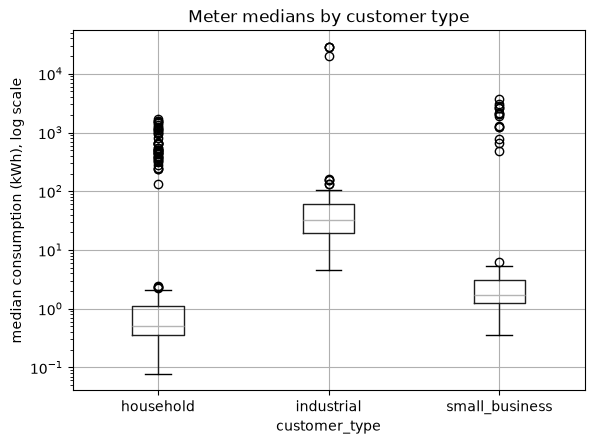

---- meters in Wh: 64
---- max ratio among the rest: 4.757746746739424
---- min ratio among Wh meters: 231.35518157661647
---- rows outside valid bounds after fix: 0


In [8]:
# TODO: D-D
meter_median = df.groupby("meter_id")["consumption_kwh"].median()  # медіана кожного лічильника
meter_type = df.groupby("meter_id")["customer_type"].first()    # customer_type кожного лічильника
type_median = df.groupby("customer_type")["consumption_kwh"].median()  # медіана всіх рядків кожного customer_type

ratio = meter_median / meter_type.map(type_median)

print("---- type medians:\n", type_median)
display(ratio.head())
# графік медіан лічильників за customer_type
medians_by_type = pd.DataFrame({"median_kwh": meter_median, "customer_type": meter_type})

medians_by_type.boxplot(column="median_kwh", by="customer_type")
plt.yscale("log")
plt.ylabel("median consumption (kWh), log scale")
plt.suptitle("")
plt.title("Meter medians by customer type")
plt.show()

# лічильники у Вт/год: відношення більше 100
is_wh = ratio > 100
wh_count = is_wh.sum()

print("---- meters in Wh:", wh_count)
print("---- max ratio among the rest:", ratio[~is_wh].max())

if wh_count > 0:
    print("---- min ratio among Wh meters:", ratio[is_wh].min())
    wh_meter_ids = ratio[is_wh].index
    df.loc[df["meter_id"].isin(wh_meter_ids), "consumption_kwh"] /= 1000
      
min_kwh = {"household": 0.01, "small_business": 0.02, "industrial": 1}
max_kwh = {"household": 10, "small_business": 60, "industrial": 1200}

low = df["customer_type"].map(min_kwh)
high = df["customer_type"].map(max_kwh)

valid_mask = df["consumption_kwh"].between(low, high)

print("---- rows outside valid bounds after fix:", (~valid_mask).sum())

## 7. Лічильники, що замовкли (D-A)

Пропуски не заповнюємо: те, що лічильник замовк, уже є інформацією про можливу відмову, а середнє її стерло б. Не видаляємо теж: до відмови лічильник передавав правильні дані.

Для кожного лічильника порахуйте, скільки годин минуло від його останнього `ts` до `2026-02-01 23:00`; більше 48 — замовк. Як на кроці 6, виведіть кількість замовклих, найбільшу тишу серед решти й найменшу серед замовклих (якщо замовклих немає — лише найбільшу тишу серед усіх).

Номери замовклих лічильників збережіть списком `silent`, наприклад `list(....index)`: він знадобиться в регресії.

Можуть допомогти `pd.Timestamp("2026-02-01 23:00")` і `/ pd.Timedelta(hours=1)`.

In [9]:
# TODO: D-A
# скільки годин минуло від останнього запису лічильника до кінця періоду
end_of_period = pd.Timestamp("2026-02-01 23:00")

last_ts = df.groupby("meter_id")["ts"].max()
silence_hours = (end_of_period - last_ts) / pd.Timedelta(hours=1)

is_silent = silence_hours > 48
silent_count = is_silent.sum()

print("---- silent meters:", silent_count)
print("---- max silence among the rest (h):", silence_hours[~is_silent].max())

if silent_count > 0:
    print("---- min silence among silent meters (h):", silence_hours[is_silent].min())

silent = list(silence_hours[is_silent].index)

---- silent meters: 48
---- max silence among the rest (h): 1.0
---- min silence among silent meters (h): 142.0


## 8. Завмерлі лічильники (D-B)

Завмерлі значення виглядають правдоподібно, і ні середнє, ні максимум їх не видають. Помітно лише те, що значення перестали змінюватися. Такі лічильники не видаляємо: частина їхніх годин справна.

Для кожного лічильника порахуйте частку різних значень `consumption_kwh` серед його записів; менше 0.65 — завмер. Побудуйте гістограму цієї частки по лічильниках. Як на кроці 6, виведіть кількість завмерлих, найменшу частку серед решти й найбільшу серед завмерлих (якщо завмерлих немає — лише найменшу частку серед усіх).

Номери завмерлих лічильників збережіть списком `frozen`: він знадобиться в регресії.

Можуть допомогти `nunique()`, `size()` і `plt.hist`.

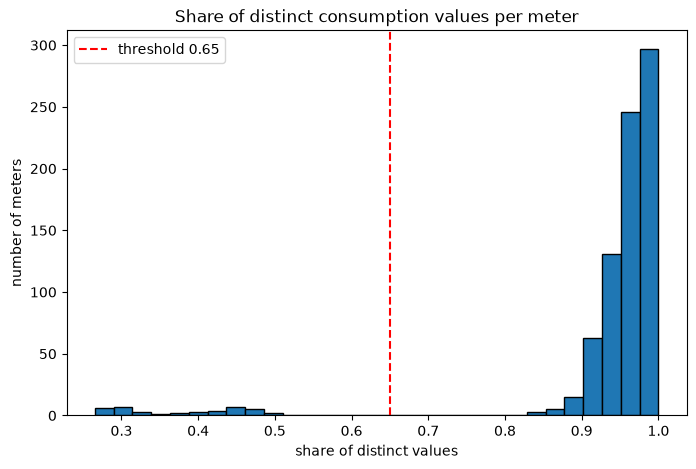

---- frozen meters: 40
---- min share among the rest: 0.8403614457831325
---- max share among frozen meters: 0.49473684210526314
---- list of frozen meters saved to 'frozen', length: 40


In [10]:
# TODO: D-B
# обчислення частки унікальних значень
unique_values = df.groupby("meter_id")["consumption_kwh"].nunique()
records_count = df.groupby("meter_id").size()
unique_share = unique_values / records_count

# гістограма частки по лічильниках
plt.figure(figsize=(8, 5))
plt.hist(unique_share, bins=30, edgecolor="black")
plt.axvline(0.65, color="red", linestyle="--", label="threshold 0.65")
plt.xlabel("share of distinct values")
plt.ylabel("number of meters")
plt.title("Share of distinct consumption values per meter")
plt.legend()
plt.show()

# визначення завмерлих лічильників 
is_frozen = unique_share < 0.65
frozen_count = is_frozen.sum()

print("---- frozen meters:", frozen_count)
print("---- min share among the rest:", unique_share[~is_frozen].min())

if frozen_count > 0:
    print("---- max share among frozen meters:", unique_share[is_frozen].max())

# збереження списку завмерлих лічильників
frozen = list(unique_share[is_frozen].index)
print("---- list of frozen meters saved to 'frozen', length:", len(frozen))

## 9. Кореляції

Колонка, що майже копіює іншу, не додає інформації: у кластеризації вона подвоює вагу того самого фактора, а в регресії робить коефіцієнти нестабільними. Технічна колонка `record_ts` після кроку 5 теж не потрібна.

Порахуйте кореляції між числовими колонками об'єднаної таблиці. Пару з кореляцією за модулем понад 0.95 вважайте копією і лиште з неї одну колонку. Приберіть `record_ts`. Підсумкову таблицю назвіть `result`.

Можуть допомогти `select_dtypes("number").corr().abs()` і `drop(columns=...)`.

In [12]:
# TODO: знайдіть і приберіть колонку-копію та record_ts

corr = df.select_dtypes("number").corr().abs()
display(corr)

# пари колонок, що копіюють одна одну (кореляція за модулем понад 0.95)
copies = []
for col_a in corr.columns:
    for col_b in corr.columns:
        if col_a < col_b and corr.loc[col_a, col_b] > 0.95:
            copies.append((col_a, col_b))

print("---- pairs of copy columns:", copies)
for col_a, col_b in copies:
    print(f"---- {col_a} and {col_b}: correlation (abs) = {corr.loc[col_a, col_b]:.4f}")

# видалення колонки копії і колонку record_ts
result = df.drop(columns=["record_ts", "years_connected"])
print(result.columns.tolist())
print(result.shape)

,consumption_kwh,electric_heating,connection_year,years_connected
consumption_kwh,1.000000,0.097382,0.009771,0.011954
electric_heating,0.097382,1.000000,0.043630,0.044338
connection_year,0.009771,0.043630,1.000000,0.999129
years_connected,0.011954,0.044338,0.999129,1.000000


---- pairs of copy columns: [('connection_year', 'years_connected')]
---- connection_year and years_connected: correlation (abs) = 0.9991
['meter_id', 'ts', 'consumption_kwh', 'customer_type', 'tariff', 'electric_heating', 'connection_year', 'district']
(516214, 8)


## 10. Самоперевірка й збереження

Якщо якась перевірка падає, поверніться до відповідного кроку.

In [13]:
districts = ["Podil", "Solomianka", "Darnytsia", "Obolon", "Sviatoshyn"]
min_kwh = {"household": 0.01, "small_business": 0.02, "industrial": 1}
max_kwh = {"household": 10, "small_business": 60, "industrial": 1200}
corr = result.select_dtypes("number").corr().abs()
copies = [(a, b) for a in corr for b in corr if a < b and corr.loc[a, b] > 0.95]

assert not result.duplicated(["meter_id", "ts"]).any(), "лишилися повтори лічильник–година"
assert result["meter_id"].nunique() == 800, "лічильників має бути 800"
assert result["meter_id"].str.fullmatch(r"UA\d{6}").all(), "є номери не у форматі UA і 6 цифр"
assert result["customer_type"].notna().all(), "є рядки без атрибутів абонента"
assert result["district"].isin(districts).all(), "є райони, яких немає в описі"
assert result["consumption_kwh"].between(result["customer_type"].map(min_kwh), result["customer_type"].map(max_kwh)).all(), "є споживання поза межами з опису"
assert not copies, f"лишилися колонки-копії: {copies}"
assert "record_ts" not in result, "технічна колонка record_ts лишилася"

result.to_parquet("cleaned.parquet", index=False)
print("усе гаразд:", result.shape)

усе гаразд: (516214, 8)


## 11. Регресія

Регресію часто використовують, щоб передбачати певні показники. Проте лінійна регресія також показує, як кожен показник впливає на результат. Це і є регресійний аналіз.

Для прикладу подивимося, як на добове споживання домогосподарства впливають електроопалення і двозонний тариф: `y = a + b₁·x₁ + b₂·x₂`.

- `y` — середнє споживання лічильника за добу, кВт·год;
- `x₁` — `electric_heating`, `x₂` — двозонний тариф (обидва 0 або 1);
- `b₁` і `b₂` — на скільки кВт·год на добу більше споживає абонент із цим фактором за однакового іншого;
- `a` — споживання без опалення на звичайному тарифі;
- R² — яку частку розкиду споживання пояснюють обидва фактори, від 0 до 1.

Регресія тут краща за просте порівняння середніх: двозонний тариф здебільшого мають будинки з опаленням, і різниця середніх за тарифом приписала б тарифу ще й споживання на опалення.

Нормалізація не потрібна: обидва фактори мають однаковий масштаб (0 або 1), тож `b₁` і `b₂` можна порівнювати напряму, а `y` лишається в кВт·год на добу, і коефіцієнти легко пояснити. Якби фактори мали різні одиниці, наприклад площу і рік, для порівняння впливу їх спершу стандартизували б.

Лічильники з `silent` і `frozen` не беремо: у `cleaned.parquet` вони лишаються, але їхнє середнє споживання спотворене.

Код майже готовий: допишіть `homes` і запустіть.

In [16]:
# TODO: homes — рядки result для домогосподарств без лічильників із silent і frozen
# кожну умову беріть у дужки: result[(умова 1) & ~(умова 2)]
is_household = result["customer_type"] == "household"
is_silent_or_frozen = result["meter_id"].isin(silent) | result["meter_id"].isin(frozen)

homes = result[is_household & ~is_silent_or_frozen]

print("---- household rows:", len(homes))
print("---- household meters:", homes["meter_id"].nunique())

per_meter = homes.groupby("meter_id").agg(
    kwh_per_day=("consumption_kwh", "mean"),
    electric_heating=("electric_heating", "first"),
    tariff=("tariff", "first"),
)
per_meter["kwh_per_day"] *= 24
per_meter["dual_zone"] = (per_meter["tariff"] == "dual_zone").astype(int)

x, y = per_meter[["electric_heating", "dual_zone"]], per_meter["kwh_per_day"]
model = LinearRegression().fit(x, y)
print("meters count:", len(per_meter))
print(f"a = {model.intercept_:.2f}, b₁ (опалення) = {model.coef_[0]:.2f}, b₂ (двозонний тариф) = {model.coef_[1]:.2f}, R² = {model.score(x, y):.3f}")

---- household rows: 318441
---- household meters: 481
meters count: 481
a = 10.39, b₁ (опалення) = 19.09, b₂ (двозонний тариф) = 2.61, R² = 0.725
